# Sujet 1 : prix de l'immobilier à Tokyo

**Cours :** Fondements et Application de Big Data, TP 3 (novembre 2026)
**Question :** combien vaut un appartement d'occasion à Tokyo ?

## Consigne

| # | À faire |
|---|---------|
| 1 | Choisir un exemple sur Kaggle, dans un domaine quelconque, **sans Big Data**, et dérouler tout le workflow : Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement |
| 2 | Refaire la même démarche en **Big Data** avec Hadoop / Spark (c'est le second notebook, `chicago_velos.ipynb`) |
| 3 | Publier le résultat sur GitHub |

Ce notebook traite le point 1. Les données tiennent dans la mémoire d'un ordinateur portable : on utilise
**pandas** pour les manipuler et **scikit-learn** pour l'apprentissage automatique.

**Source :** le jeu Kaggle [Japan Real Estate Prices](https://www.kaggle.com/datasets/nishiodens/japan-real-estate-transaction-prices)
(nishiodens). Il reprend les relevés du ministère japonais des Transports et du Territoire (MLIT) : chaque
trimestre, le ministère interroge les acheteurs sur le prix payé. Le jeu complet couvre les 47 préfectures
(environ 1 Go) ; on n'en prend qu'**un fichier, celui de Tokyo** (préfecture n° 13, 104 Mo).

## Plan

1. Data : charger et comprendre les données
2. EDA : explorer avec des graphiques
3. Prétraitement : nettoyer
4. Transformation : fabriquer les variables du modèle
5. ML : entraîner et comparer quatre modèles
6. Évaluation : mesurer les erreurs, comprendre le modèle
7. Déploiement : sauvegarder le modèle et le servir dans une petite appli
8. Bilan des tests et conclusion

In [1]:
import sys, time, json, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn, joblib

from outils import (style, verifier, bilan_tests, schema, workflow,
                    BLEU, ORANGE, VERT_EAU, JAUNE, VIOLET, ROUGE, GRIS, ENCRE_2, SEQUENTIEL)
import tokyo_prep

style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Python       :", sys.version.split()[0])
print("Système      :", platform.system(), platform.release())
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)

Python       : 3.11.9
Système      : Windows 10
pandas       : 2.3.0
scikit-learn : 1.8.0


Le workflow demandé, que l'on suit étape par étape. À chaque partie, l'étape en cours est en orange.

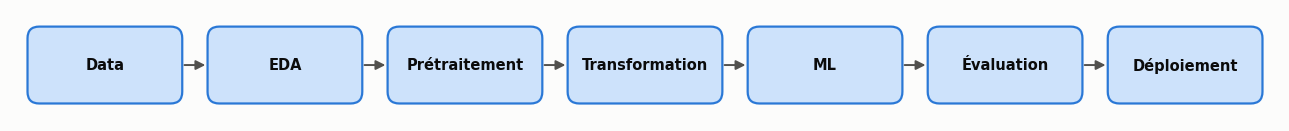

In [2]:
workflow()

### Les tests

Tout au long du notebook, une petite fonction `verifier` (dans `outils.py`) contrôle nos résultats : nombre
de lignes, absence de valeurs manquantes, modèle meilleur que la règle simple, modèle rechargé identique...
Le bilan de tous les tests est affiché à la fin.

## 1. Data : charger et comprendre les données

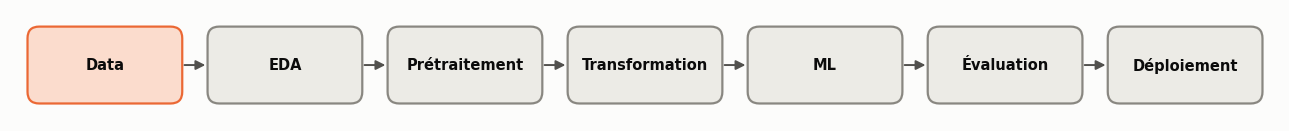

In [3]:
workflow(actif=1)

Le fichier est téléchargé une seule fois avec `kagglehub` (pas besoin de compte Kaggle pour un jeu public),
puis copié dans `data/tokyo/`. Le dossier `data/` n'est pas versionné.

In [4]:
FICHIER = Path("data/tokyo/13.csv")
if not FICHIER.exists():
    import kagglehub, shutil
    chemin = kagglehub.dataset_download("nishiodens/japan-real-estate-transaction-prices",
                                        path="trade_prices/13.csv")
    FICHIER.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(chemin, FICHIER)

t0 = time.perf_counter()
brut = pd.read_csv(FICHIER, low_memory=False)
print(f"Lu en {time.perf_counter() - t0:.1f} s : {len(brut):,} ventes, {brut.shape[1]} colonnes, "
      f"{FICHIER.stat().st_size / 1e6:.0f} Mo sur le disque, "
      f"{brut.memory_usage(deep=True).sum() / 1e6:.0f} Mo en mémoire")
verifier("406 575 ventes et 38 colonnes dans le fichier de Tokyo", brut.shape == (406575, 38), brut.shape)
brut.head(3).T

Lu en 1.4 s : 406,575 ventes, 38 colonnes, 104 Mo sur le disque, 494 Mo en mémoire
OK     406 575 ventes et 38 colonnes dans le fichier de Tokyo  ((406575, 38))


,0,1,2
No,1,2,3
Type,"Pre-owned Condominiums, etc.","Pre-owned Condominiums, etc.",Residential Land(Land and Building)
Region,NaN,NaN,Commercial Area
MunicipalityCode,13101,13101,13101
Prefecture,Tokyo,Tokyo,Tokyo
Municipality,Chiyoda Ward,Chiyoda Ward,Chiyoda Ward
DistrictName,Iidabashi,Iidabashi,Iidabashi
NearestStation,Iidabashi,Iidabashi,Iidabashi
TimeToNearestStation,4,4,2
MinTimeToNearestStation,4.00,4.00,2.00


Une ligne est **une vente**. Le fichier mélange cinq types de biens :

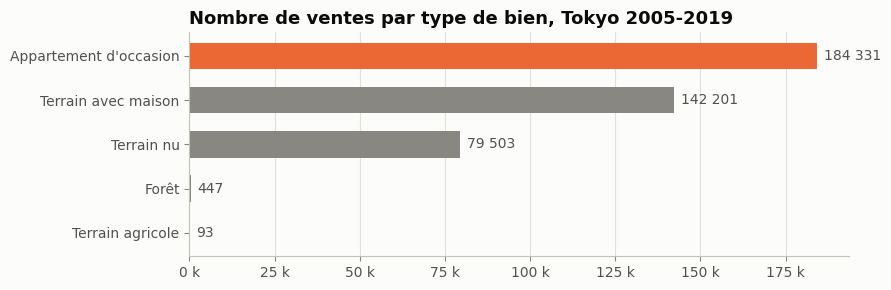

In [5]:
types = brut["Type"].value_counts()
noms = {"Pre-owned Condominiums, etc.": "Appartement d'occasion",
        "Residential Land(Land and Building)": "Terrain avec maison",
        "Residential Land(Land Only)": "Terrain nu",
        "Forest Land": "Forêt", "Agricultural Land": "Terrain agricole"}

fig, ax = plt.subplots(figsize=(9, 3))
couleurs = [ORANGE if t.startswith("Pre-owned") else GRIS for t in types.index]
ax.barh([noms[t] for t in types.index][::-1], types.values[::-1], color=couleurs[::-1], height=0.6)
for i, v in enumerate(types.values[::-1]):
    ax.text(v + 2000, i, f"{v:,}".replace(",", " "), va="center", color=ENCRE_2)
ax.set_title("Nombre de ventes par type de bien, Tokyo 2005-2019")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f} k"))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

On garde les **appartements d'occasion** (en orange), le type le plus fréquent. Mélanger un appartement, une
maison et une forêt n'aurait pas de sens : leurs prix ne dépendent pas des mêmes choses (pour un terrain,
c'est surtout la surface du sol ; pour un appartement, la surface habitable, l'âge, la gare...).

Les colonnes utiles pour un appartement :

| Colonne | Signification | Exemple |
|---|---|---|
| `TradePrice` | **prix de vente en yens** : c'est ce qu'on veut prédire | 40 000 000 |
| `Municipality` | commune : un des 23 arrondissements (*Ward*) ou une ville de la banlieue ouest (*City*) | Chiyoda Ward |
| `NearestStation` | gare la plus proche | Iidabashi |
| `MinTimeToNearestStation` | minutes à pied jusqu'à la gare | 4 |
| `Area` | surface en m² | 30 |
| `FloorPlan` | plan à la japonaise : nombre de pièces + L (salon), D (salle à manger), K (cuisine), S (pièce en plus) | 1LDK |
| `BuildingYear` | année de construction de l'immeuble | 2013 |
| `Structure` | RC = béton armé, SRC = béton armé + acier, S = acier | RC |
| `Renovation` | appartement rénové ou non | Not yet |
| `CityPlanning` | zonage d'urbanisme (zone commerciale, résidentielle...) | Commercial Zone |
| `CoverageRatio`, `FloorAreaRatio` | règles d'urbanisme : part du terrain bâtie, densité autorisée (en %) | 80, 500 |
| `Year`, `Quarter` | année et trimestre de la vente | 2019, 3 |
| `Remarks` | remarque : vente aux enchères, entre proches... | |

184,331 appartements d'occasion
OK     184 331 appartements d'occasion  (184331)


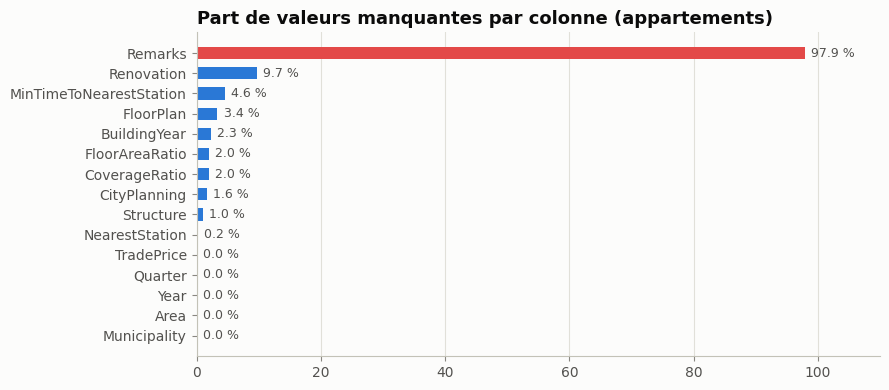

In [6]:
appart = brut[brut["Type"] == "Pre-owned Condominiums, etc."].copy()
print(f"{len(appart):,} appartements d'occasion")
verifier("184 331 appartements d'occasion", len(appart) == 184331, len(appart))

manquants = (appart[tokyo_prep.COLONNES_BRUTES + ["TradePrice", "Remarks"]].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(manquants.index, manquants.values, color=[ROUGE if v > 50 else BLEU for v in manquants.values], height=0.6)
for i, v in enumerate(manquants.values):
    ax.text(v + 1, i, f"{v:.1f} %", va="center", color=ENCRE_2, fontsize=9)
ax.set_title("Part de valeurs manquantes par colonne (appartements)")
ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Les colonnes importantes sont presque complètes : quelques pour cent de manquants sur l'année de construction,
le temps jusqu'à la gare et le plan. `Remarks` est vide à 98 % : c'est normal, elle ne sert qu'à signaler les
ventes particulières.

## 2. EDA : explorer les données

L'EDA (*Exploratory Data Analysis*) sert à **comprendre les données avant de modéliser** : ordres de grandeur,
valeurs bizarres, liens entre le prix et les autres colonnes. Ce qu'on y voit guide le nettoyage et le choix
des variables.

On ajoute deux colonnes pour lire plus facilement : le prix en **millions de yens** (M¥) et le **prix au m²**
en milliers de yens (k¥/m²), qui permet de comparer des appartements de tailles différentes.

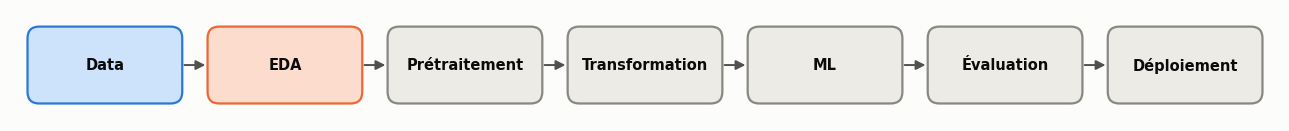

In [7]:
workflow(actif=2)

In [8]:
appart["prix_M"] = appart["TradePrice"] / 1e6
appart["prix_m2_k"] = appart["TradePrice"] / appart["Area"] / 1e3
appart[["prix_M", "Area", "prix_m2_k", "BuildingYear", "MinTimeToNearestStation"]].describe(
    percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
prix_M,"184,331.00",31.21,38.15,0.00,3.60,17.00,25.00,38.00,120.00,"8,600.00"
Area,"184,331.00",48.26,28.22,10.00,15.00,25.00,50.00,65.00,115.00,"2,000.00"
prix_m2_k,"184,331.00",679.63,390.39,0.03,120.00,428.57,622.22,900.00,"1,550.00","20,000.00"
BuildingYear,"180,041.00","1,996.78",11.97,"1,945.00","1,969.00","1,988.00","2,000.00","2,006.00","2,016.00","2,019.00"
MinTimeToNearestStation,"175,861.00",7.71,5.52,0.00,1.00,4.00,7.00,10.00,28.00,120.00


### 2.1 Le prix : une distribution très étalée

Le prix médian est de 25 M¥, mais le maximum dépasse 8 milliards de yens : une vente d'immeuble entier
enregistrée comme « appartement », sans doute. À gauche, l'échelle normale écrase tout ; à droite, avec une
**échelle logarithmique**, la distribution devient une jolie cloche. On s'en souviendra pour la transformation :
on prédira le **logarithme du prix**.

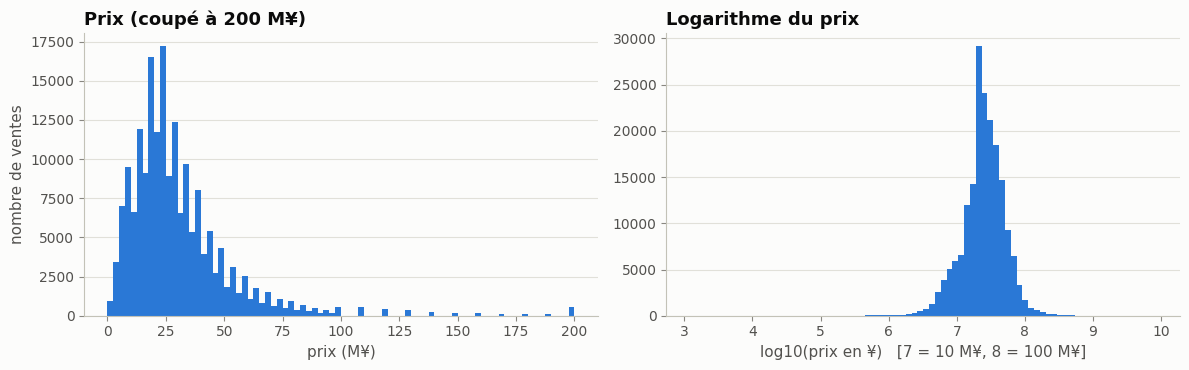

In [9]:
fig, (g, d) = plt.subplots(1, 2, figsize=(12, 3.8))
g.hist(appart["prix_M"].clip(upper=200), bins=80, color=BLEU)
g.set_title("Prix (coupé à 200 M¥)"); g.set_xlabel("prix (M¥)"); g.set_ylabel("nombre de ventes")
d.hist(np.log10(appart["TradePrice"]), bins=80, color=BLEU)
d.set_title("Logarithme du prix"); d.set_xlabel("log10(prix en ¥)   [7 = 10 M¥, 8 = 100 M¥]")
for ax in (g, d): ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 2.2 Où est-ce le plus cher ?

Prix médian au m² par commune. Les 23 arrondissements (*Ward*, en bleu) forment la ville de Tokyo proprement
dite ; les villes (*City*, en gris) sont la banlieue ouest, la région de Tama.

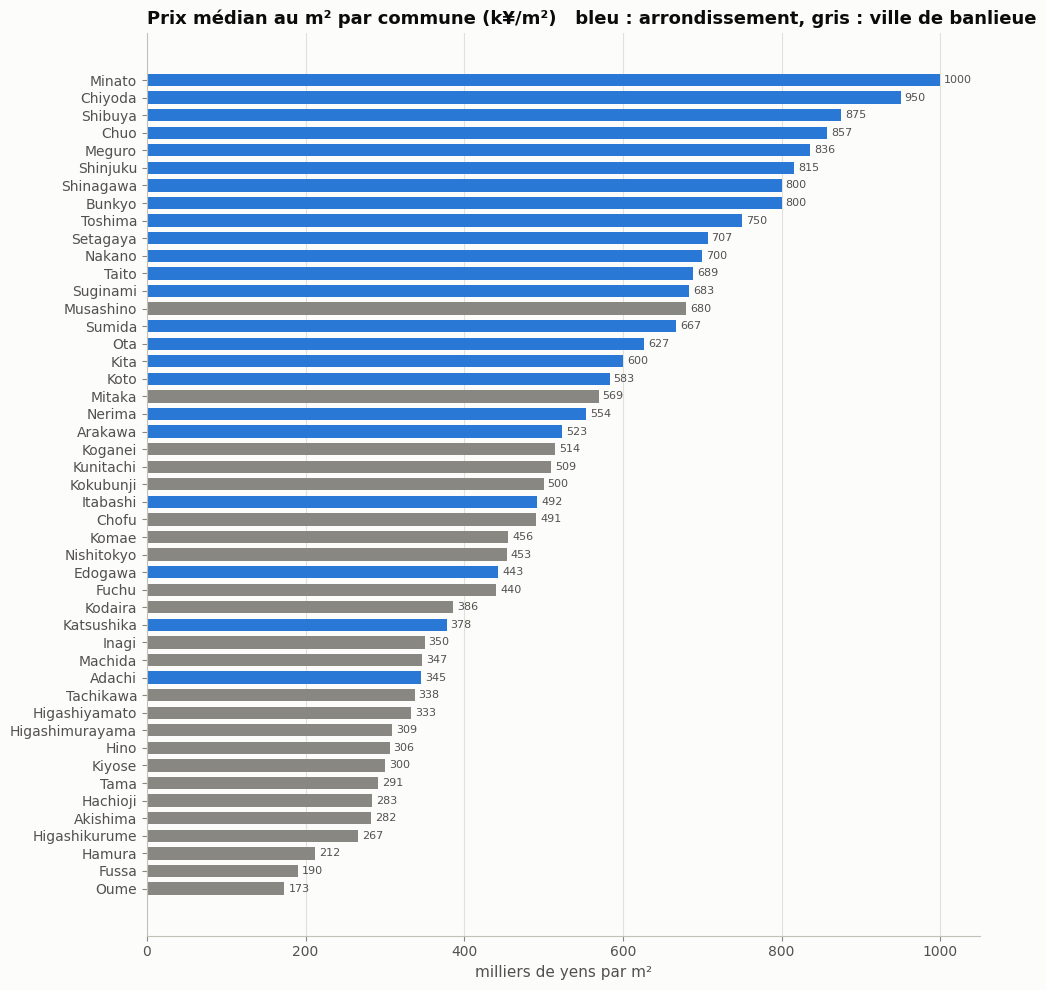

              prix_m2  ventes
Municipality                 
Shibuya Ward   875.00    6144
Chiyoda Ward   950.00    3029
Minato Ward  1,000.00   10224 
               prix_m2  ventes
Municipality                 
Oume City      173.00    1172
Fussa City     190.00     323
Hamura City    212.00     238


In [10]:
par_commune = appart.groupby("Municipality").agg(prix_m2=("prix_m2_k", "median"), ventes=("prix_m2_k", "size"))
par_commune = par_commune[par_commune["ventes"] >= 100].sort_values("prix_m2")
fig, ax = plt.subplots(figsize=(10, 10))
coul = [BLEU if m.endswith("Ward") else GRIS for m in par_commune.index]
ax.barh([m.replace(" Ward", "").replace(" City", "") for m in par_commune.index], par_commune["prix_m2"],
        color=coul, height=0.7)
for i, v in enumerate(par_commune["prix_m2"]):
    ax.text(v + 5, i, f"{v:.0f}", va="center", fontsize=8, color=ENCRE_2)
ax.set_title("Prix médian au m² par commune (k¥/m²)   bleu : arrondissement, gris : ville de banlieue")
ax.set_xlabel("milliers de yens par m²"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(par_commune.tail(3).round(0), "\n", par_commune.head(3).round(0))

L'écart est énorme : le m² vaut environ **5 à 6 fois plus** à Minato, Chiyoda ou Shibuya (le centre) que
dans les villes éloignées comme Oume. **La commune sera une variable essentielle.**

### 2.3 Surface, âge, distance à la gare

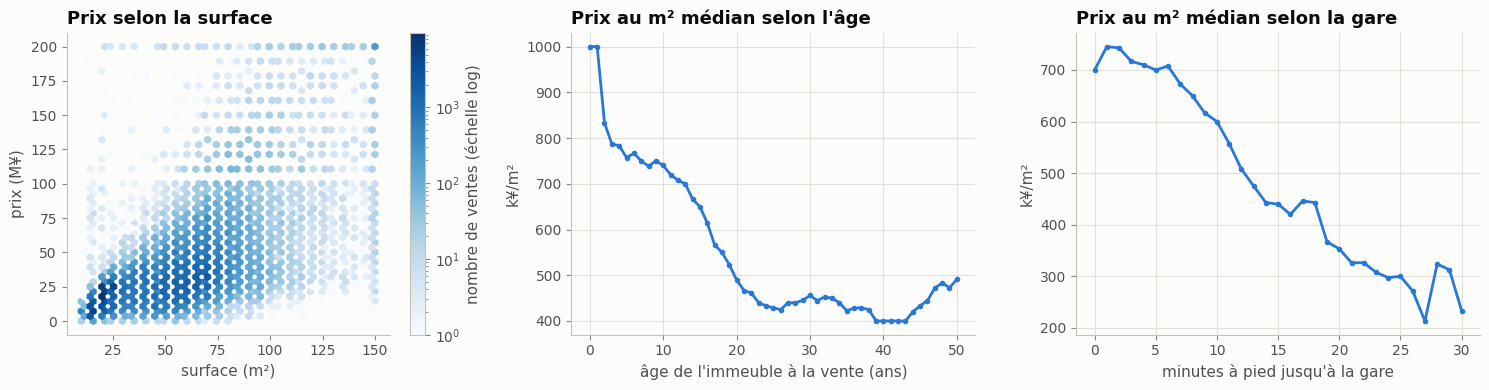

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
hb = ax.hexbin(appart["Area"].clip(upper=150), appart["prix_M"].clip(upper=200), gridsize=50,
               bins="log", cmap=SEQUENTIEL, mincnt=1)
ax.set_title("Prix selon la surface"); ax.set_xlabel("surface (m²)"); ax.set_ylabel("prix (M¥)")
ax.grid(False); fig.colorbar(hb, ax=ax, label="nombre de ventes (échelle log)")

ax = axes[1]
age = (appart["Year"] - appart["BuildingYear"])
med = appart.groupby(age.clip(0, 50))["prix_m2_k"].median()
ax.plot(med.index, med.values, color=BLEU, marker="o", markersize=3)
ax.set_title("Prix au m² médian selon l'âge"); ax.set_xlabel("âge de l'immeuble à la vente (ans)")
ax.set_ylabel("k¥/m²")

ax = axes[2]
med = appart.groupby(appart["MinTimeToNearestStation"].clip(upper=30))["prix_m2_k"].median()
ax.plot(med.index, med.values, color=BLEU, marker="o", markersize=3)
ax.set_title("Prix au m² médian selon la gare"); ax.set_xlabel("minutes à pied jusqu'à la gare")
ax.set_ylabel("k¥/m²")
plt.tight_layout(); plt.show()

- **Surface** : le prix monte avec la surface, mais le nuage est très large (à surface égale, le prix varie
  du simple au quintuple selon le quartier). La plupart des ventes font 20 à 80 m².
- **Âge** : le prix au m² baisse nettement pendant les 25 premières années, puis se stabilise (on achète alors
  surtout l'emplacement). La remontée tout à droite concerne peu de ventes, souvent des immeubles anciens du centre.
- **Gare** : chaque minute de marche en plus fait baisser le prix au m². À Tokyo, tout le monde prend le train.

### 2.4 L'évolution dans le temps

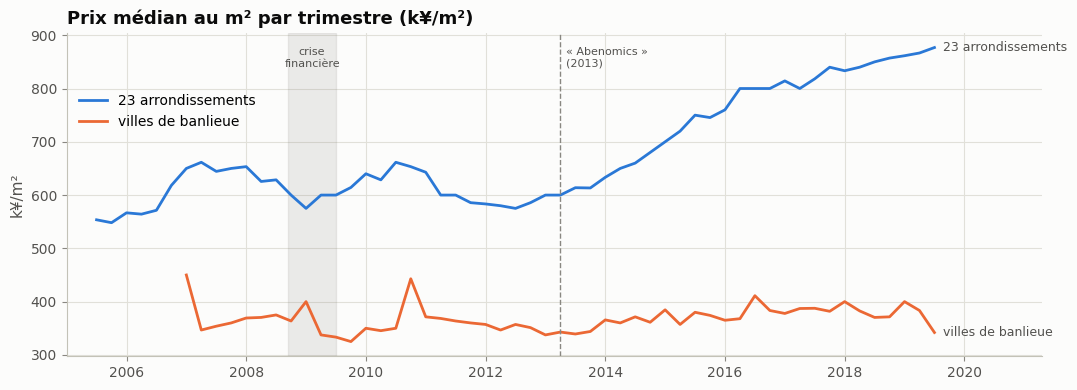

In [12]:
appart["date"] = appart["Year"] + (appart["Quarter"] - 1) / 4
zone = np.where(appart["Municipality"].str.endswith("Ward"), "23 arrondissements", "villes de banlieue")
evol = appart.groupby([zone, "date"])["prix_m2_k"].median().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4))
for col, c in zip(evol.columns, [BLEU, ORANGE]):
    ax.plot(evol.index, evol[col], color=c, label=col)
    ax.text(evol.index[-1] + 0.15, evol[col].iloc[-1], col, color=ENCRE_2, va="center", fontsize=9)
ax.axvspan(2008.7, 2009.5, color=GRIS, alpha=0.15)
ax.text(2009.1, ax.get_ylim()[1] * 0.97, "crise\nfinancière", ha="center", va="top", fontsize=8, color=ENCRE_2)
ax.axvline(2013.25, color=GRIS, ls="--", lw=1)
ax.text(2013.35, ax.get_ylim()[1] * 0.97, "« Abenomics »\n(2013)", va="top", fontsize=8, color=ENCRE_2)
ax.set_title("Prix médian au m² par trimestre (k¥/m²)"); ax.set_xlim(2005, 2021.3)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.85)); ax.set_ylabel("k¥/m²")
plt.tight_layout(); plt.show()

Les prix baissent avec la crise financière de 2008, puis montent fortement à partir de 2013 (politique de
relance « Abenomics », Jeux olympiques attribués à Tokyo en 2013) : près de +50 % dans les 23 arrondissements
entre 2012 et 2019 (de 590 à 870 k¥/m² environ), alors que la banlieue reste presque stable. **La date de vente
compte donc aussi.**

### 2.5 Le plan des appartements

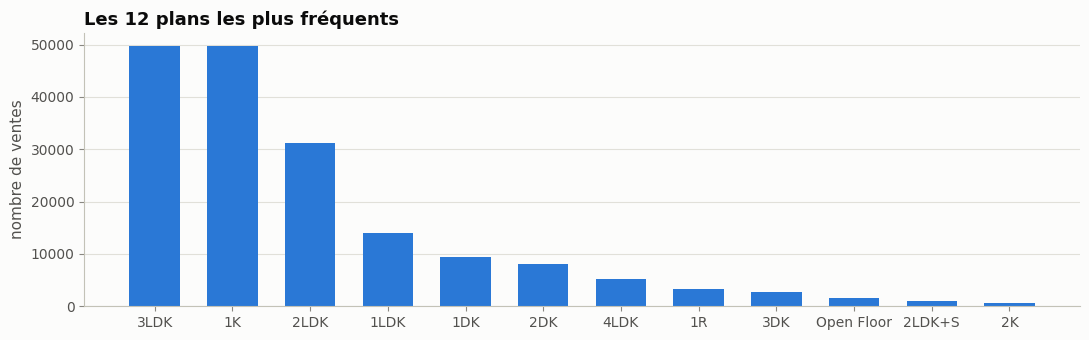

In [13]:
plans = appart["FloorPlan"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(plans.index, plans.values, color=BLEU, width=0.65)
ax.set_title("Les 12 plans les plus fréquents"); ax.set_ylabel("nombre de ventes")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Deux familles dominent : le **1K** (une pièce + coin cuisine, le studio typique des célibataires, souvent
acheté pour être loué) et le **3LDK** (trois chambres + salon/salle à manger/cuisine, l'appartement familial).
Le plan est une chaîne de caractères : on en tirera des nombres (nombre de pièces, présence d'un salon...).

### 2.6 Corrélations entre variables numériques

La **corrélation** mesure à quel point deux colonnes varient ensemble : +1 = elles montent ensemble, −1 = l'une
monte quand l'autre descend, 0 = pas de lien linéaire. Couleurs : bleu = lien positif, rouge = lien négatif.

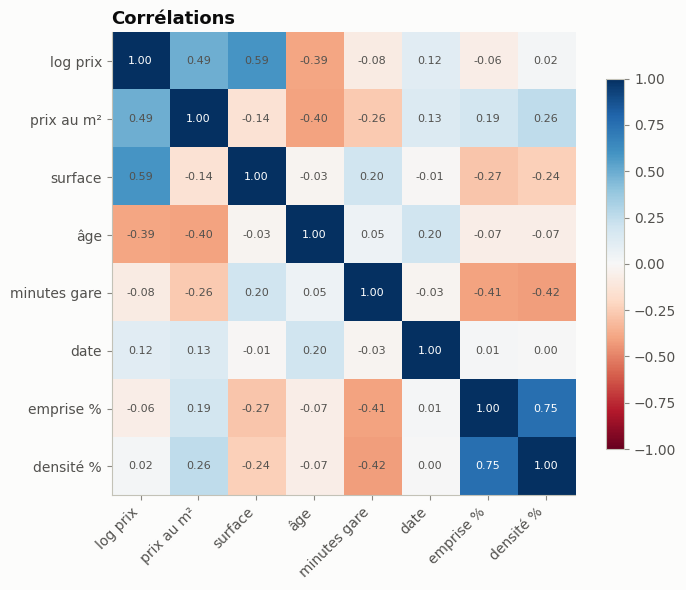

In [14]:
num = pd.DataFrame({"log prix": np.log(appart["TradePrice"]), "prix au m²": appart["prix_m2_k"],
                    "surface": appart["Area"], "âge": appart["Year"] - appart["BuildingYear"],
                    "minutes gare": appart["MinTimeToNearestStation"], "date": appart["date"],
                    "emprise %": appart["CoverageRatio"], "densité %": appart["FloorAreaRatio"]})
corr = num.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else ENCRE_2)
ax.grid(False); ax.set_title("Corrélations"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

- Le log du prix est surtout lié à la **surface** (+), à l'**âge** (−) et à la **densité autorisée** (+ : les
  zones très denses sont les quartiers centraux).
- Le **prix au m²** est lié à l'âge, à la densité et à la gare, mais presque pas à la surface : c'est
  l'emplacement et l'état qui le fixent.
- Aucune paire de variables n'est presque identique (pas de corrélation proche de ±1 entre deux variables
  explicatives) : on peut toutes les garder.

**Ce que l'EDA nous apprend pour la suite :** prédire le log du prix ; garder la commune, la gare, la surface,
l'âge, les minutes à pied et la date ; se méfier des prix extrêmes (enchères, immeubles entiers...).

## 3. Prétraitement : nettoyer

On enlève les lignes qui fausseraient l'apprentissage. Chaque règle est justifiée et on compte ce qu'elle
retire.

| Étape | Règle | Pourquoi |
|---|---|---|
| a | enlever les ventes avec une remarque | enchères, ventes entre proches, hypothèque... : le prix n'est pas celui du marché |
| b | garder l'usage « logement » (ou non précisé) | un bureau ou un commerce ne se vend pas au même prix |
| c | enlever les doublons exacts | une même vente comptée deux fois pèserait double |
| d | enlever les lignes sans année de construction, sans gare ou sans temps de trajet | variables essentielles ; elles ne manquent que sur quelques % des lignes |
| e | garder les surfaces de 15 à 150 m² | en dessous, des chambres ou erreurs ; au-dessus, souvent des immeubles entiers |
| f | garder les prix au m² entre les centiles 0,5 % et 99,5 % | prix aberrants (1 200 ¥ l'appartement, 20 M¥ le m²). ⚠️ Seule règle qui regarde le prix : une vraie annonce ne peut pas être filtrée ainsi, d'où une mesure à part sur ces ventes en 6 |
| g | garder un âge positif | un immeuble construit après la vente est une erreur de saisie |

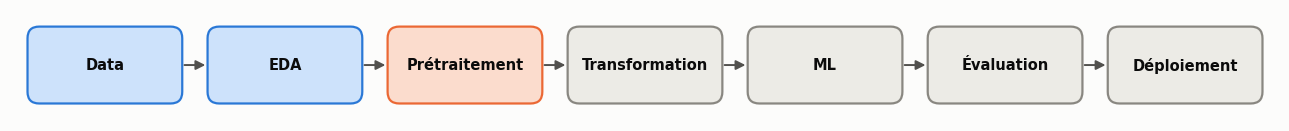

In [15]:
workflow(actif=3)

In [16]:
etapes = [("départ : appartements d'occasion", appart)]
d = appart[appart["Remarks"].isna()];                                   etapes.append(("a. sans remarque", d))
d = d[d["Use"].isna() | (d["Use"] == "House")];                         etapes.append(("b. usage logement", d))
d = d.drop_duplicates(subset=[c for c in d.columns if c != "No"]);      etapes.append(("c. sans doublon", d))
d = d.dropna(subset=["BuildingYear", "NearestStation", "MinTimeToNearestStation"])
etapes.append(("d. variables essentielles présentes", d))
d = d[d["Area"].between(15, 150)];                                      etapes.append(("e. surface 15-150 m²", d))
bas, haut = d["prix_m2_k"].quantile([0.005, 0.995])
avant_f = d
d = d[d["prix_m2_k"].between(bas, haut)];                               etapes.append(("f. prix au m² hors extrêmes", d))
d = d[d["Year"] >= d["BuildingYear"]];                                  etapes.append(("g. âge positif", d))
propre = d.copy()
# Ventes écartées par la règle f (seule règle qui regarde le prix) : on mesurera le modèle dessus en 6.
exclus_f = avant_f[~avant_f.index.isin(propre.index) & (avant_f["Year"] >= avant_f["BuildingYear"])]

compte = pd.DataFrame({"étape": [e for e, _ in etapes], "lignes": [len(x) for _, x in etapes]})
compte["retirées"] = -compte["lignes"].diff().fillna(0).astype(int)
print(f"Prix au m² gardés : de {bas:.0f} à {haut:.0f} k¥/m²")
compte

Prix au m² gardés : de 92 à 1765 k¥/m²


,étape,lignes,retirées
0,départ : appartements d'occasion,184331,0
1,a. sans remarque,180507,3824
2,b. usage logement,178453,2054
3,c. sans doublon,175161,3292
4,d. variables essentielles présentes,163532,11629
5,e. surface 15-150 m²,162612,920
6,f. prix au m² hors extrêmes,160989,1623
7,g. âge positif,160626,363


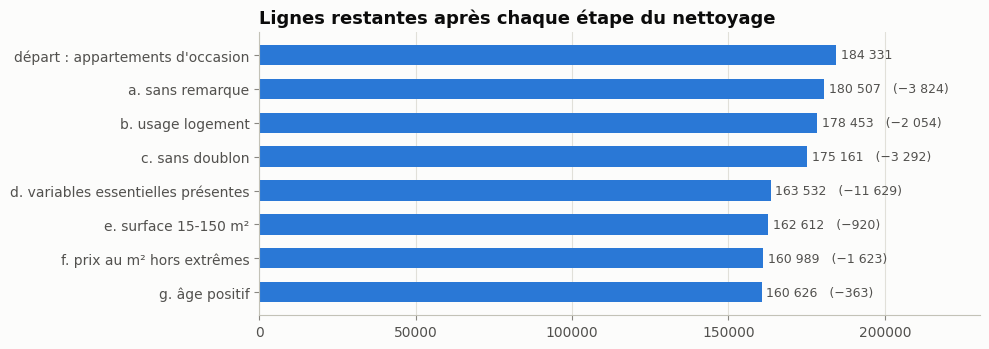

On garde 160,626 ventes, soit 87.1% des appartements.
OK     le nettoyage garde plus de 85 % des appartements  (87.1%)


OK     plus aucun doublon
OK     aucun âge négatif


In [17]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(compte["étape"][::-1], compte["lignes"][::-1], color=BLEU, height=0.6)
for i, (n, r) in enumerate(zip(compte["lignes"][::-1], compte["retirées"][::-1])):
    ax.text(n + 1500, i, f"{n:,}".replace(",", " ") + (f"   (−{r:,})".replace(",", " ") if r else ""),
            va="center", fontsize=9, color=ENCRE_2)
ax.set_xlim(0, compte["lignes"].max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_title("Lignes restantes après chaque étape du nettoyage")
plt.tight_layout(); plt.show()

part = len(propre) / len(appart)
print(f"On garde {len(propre):,} ventes, soit {part:.1%} des appartements.")
verifier("le nettoyage garde plus de 85 % des appartements", part > 0.85, f"{part:.1%}")
verifier("plus aucun doublon", not propre.duplicated(subset=[c for c in propre.columns if c != "No"]).any())
verifier("aucun âge négatif", (propre["Year"] >= propre["BuildingYear"]).all())

## 4. Transformation : fabriquer les variables

Un modèle ne comprend que des **nombres**. Il faut donc transformer chaque colonne brute :

| Variable du modèle | Calcul |
|---|---|
| `surface_m2`, `minutes_gare`, `taux_emprise`, `taux_densite` | repris tels quels |
| `age_ans` | année de vente − année de construction |
| `date` | année + trimestre (2019 T3 → 2019,5) |
| `nb_pieces`, `salon`, `salle_a_manger`, `cuisine`, `piece_en_plus` | lus dans le plan : « 2LDK+S » → 2 pièces, salon 1, salle à manger 1, cuisine 1, pièce en plus 1 |
| `renove` | 1 si rénové, 0 sinon |
| `arrondissement_23` | 1 pour les 23 arrondissements du centre, 0 pour la banlieue |
| `commune`, `structure`, `zonage` | catégories → **encodage one-hot** : une colonne 0/1 par valeur possible |
| `gare` | 600 gares, trop pour le one-hot → **encodage par la cible** : chaque gare est remplacée par le log du prix moyen des ventes proches de cette gare (calculé sans tricher, voir plus bas) |
| **cible** | **log(prix)** |

Ces calculs sont écrits une seule fois dans `tokyo_prep.py`. L'appli de déploiement réutilise ce fichier, ce
qui garantit qu'elle prépare les données exactement comme à l'entraînement.

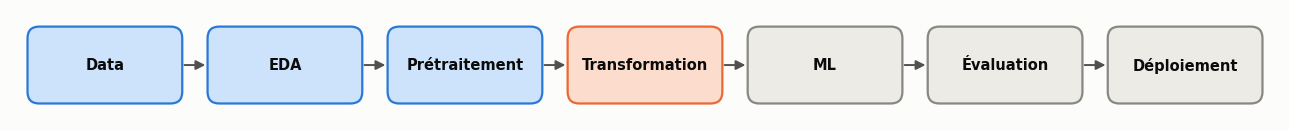

In [18]:
workflow(actif=4)

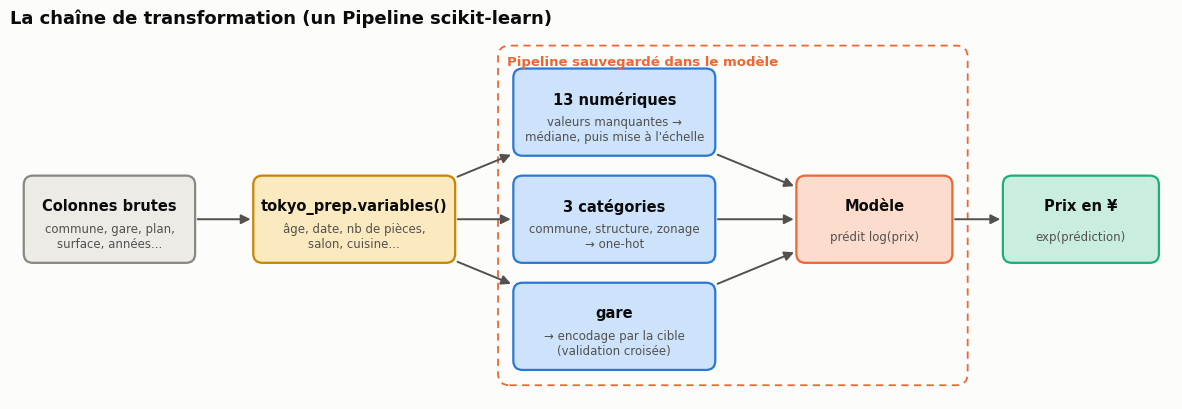

In [19]:
schema([
    dict(id="brut", x=0, y=1.2, texte="Colonnes brutes", sous="commune, gare, plan,\nsurface, années...", couleur="gris", l=2.2, h=1.1),
    dict(id="prep", x=3.2, y=1.2, texte="tokyo_prep.variables()", sous="âge, date, nb de pièces,\nsalon, cuisine...", couleur="jaune", l=2.6, h=1.1),
    dict(id="num", x=6.6, y=2.6, texte="13 numériques", sous="valeurs manquantes →\nmédiane, puis mise à l'échelle", couleur="bleu", l=2.6, h=1.1),
    dict(id="cat", x=6.6, y=1.2, texte="3 catégories", sous="commune, structure, zonage\n→ one-hot", couleur="bleu", l=2.6, h=1.1),
    dict(id="gare", x=6.6, y=-0.2, texte="gare", sous="→ encodage par la cible\n(validation croisée)", couleur="bleu", l=2.6, h=1.1),
    dict(id="mod", x=10, y=1.2, texte="Modèle", sous="prédit log(prix)", couleur="orange", l=2.0, h=1.1),
    dict(id="sortie", x=12.7, y=1.2, texte="Prix en ¥", sous="exp(prédiction)", couleur="vert", l=2.0, h=1.1),
], [("brut", "prep"), ("prep", "num"), ("prep", "cat"), ("prep", "gare"), ("num", "mod"), ("cat", "mod"),
    ("gare", "mod"), ("mod", "sortie")],
   taille=(14, 4.2), titre="La chaîne de transformation (un Pipeline scikit-learn)",
   cadres=[dict(x0=5.1, y0=-0.95, x1=11.2, y1=3.45, texte="Pipeline sauvegardé dans le modèle", couleur="orange")])

In [20]:
X = tokyo_prep.variables(propre)
y = np.log(propre["TradePrice"].to_numpy())
print(X.shape)
verifier("aucune valeur manquante dans la cible", not np.isnan(y).any())
plans_test = propre.iloc[[0] * 3].assign(FloorPlan=["2LDK+S", "1K", "1R"])
lus = tokyo_prep.variables(plans_test)[["nb_pieces", "salon", "salle_a_manger", "cuisine", "piece_en_plus"]]
verifier("les plans 2LDK+S, 1K et 1R sont bien lus (pièces, L, D, K, S)",
         lus.to_numpy().tolist() == [[2, 1, 1, 1, 1], [1, 0, 0, 1, 0], [1, 0, 0, 0, 0]], lus.to_numpy().tolist())
X.head()

(160626, 17)
OK     aucune valeur manquante dans la cible
OK     les plans 2LDK+S, 1K et 1R sont bien lus (pièces, L, D, K, S)  ([[2.0, 1.0, 1.0, 1.0, 1.0], [1.0, 0.0, 0.0, 1.0, 0.0], [1.0, 0.0, 0.0, 0.0, 0.0]])


,surface_m2,age_ans,minutes_gare,nb_pieces,salon,salle_a_manger,cuisine,piece_en_plus,renove,taux_emprise,taux_densite,date,arrondissement_23,commune,structure,zonage,gare
0,30.00,6.00,4.00,1.00,1.00,1.00,1.00,0.00,0.00,80.00,500.00,"2,019.50",1.00,Chiyoda Ward,RC,Commercial Zone,Iidabashi
1,80.00,12.00,4.00,3.00,1.00,1.00,1.00,0.00,1.00,80.00,500.00,"2,019.50",1.00,Chiyoda Ward,RC,Commercial Zone,Iidabashi
4,65.00,12.00,4.00,2.00,1.00,1.00,1.00,0.00,1.00,80.00,500.00,"2,019.25",1.00,Chiyoda Ward,RC,Commercial Zone,Iidabashi
6,35.00,33.00,3.00,1.00,1.00,1.00,1.00,0.00,0.00,80.00,700.00,"2,018.75",1.00,Chiyoda Ward,SRC,Commercial Zone,Iidabashi
7,20.00,36.00,4.00,1.00,0.00,0.00,1.00,0.00,0.00,80.00,700.00,"2,018.50",1.00,Chiyoda Ward,SRC,Commercial Zone,Iidabashi


**Découpage apprentissage / test.** On met de côté 20 % des ventes, tirées au hasard, que le modèle ne verra
jamais pendant l'entraînement : c'est sur elles qu'on mesurera ses erreurs. Sinon, on mesurerait sa capacité à
**apprendre par cœur**, pas à prédire.

In [21]:
from sklearn.model_selection import train_test_split
X_app, X_test, y_app, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"apprentissage : {len(X_app):,} ventes   test : {len(X_test):,} ventes")
verifier("aucune vente à la fois en apprentissage et en test", len(set(X_app.index) & set(X_test.index)) == 0)
# Deux ventes différentes peuvent avoir exactement les mêmes variables (même immeuble, même plan, même trimestre).
jumelles = X_test.merge(X_app.drop_duplicates(), how="inner").shape[0]
print(f"ventes de test dont les 17 variables existent telles quelles dans l'apprentissage : {jumelles:,} "
      f"({jumelles / len(X_test):.1%})")

apprentissage : 128,500 ventes   test : 32,126 ventes
OK     aucune vente à la fois en apprentissage et en test
ventes de test dont les 17 variables existent telles quelles dans l'apprentissage : 1,593 (5.0%)


Le **Pipeline** enchaîne la préparation et le modèle. Les moyennes, médianes et encodages sont calculés
**seulement sur les données d'apprentissage**, puis appliqués tels quels au test : sinon, des informations du
test fuiraient dans le modèle et ses scores seraient trop beaux.

Pour l'encodage de la gare, `TargetEncoder` va plus loin : même sur l'apprentissage, il calcule la moyenne
d'une gare **sans la vente elle-même** (par validation croisée interne), pour que le modèle ne lise pas la
réponse dans ses variables.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

def preparation():
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), tokyo_prep.NUMERIQUES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), tokyo_prep.CATEGORIELLES),
        ("gare", TargetEncoder(target_type="continuous", random_state=0), tokyo_prep.GARE),
    ])

apercu = preparation().fit(X_app, y_app)
noms_colonnes = apercu.get_feature_names_out()
print(f"{len(tokyo_prep.VARIABLES)} variables deviennent {len(noms_colonnes)} colonnes numériques après encodage")
print(list(noms_colonnes[:5]), "...", list(noms_colonnes[-3:]))

17 variables deviennent 81 colonnes numériques après encodage
['num__surface_m2', 'num__age_ans', 'num__minutes_gare', 'num__nb_pieces', 'num__salon'] ... ['cat__zonage_inconnu', 'cat__zonage_infrequent_sklearn', 'gare__gare']


## 5. ML : entraîner et comparer quatre modèles

On compare des modèles de plus en plus riches, du plus simple au plus complexe :

| Modèle | Idée |
|---|---|
| **Règle simple** (référence) | prix au m² médian de la commune × surface. Pas d'apprentissage : c'est ce que ferait un agent immobilier pressé. Un modèle doit faire mieux, sinon il ne sert à rien. |
| **Régression linéaire** (Ridge) | log(prix) = somme pondérée des variables. Simple et lisible, mais ne voit que des effets en ligne droite. |
| **Forêt aléatoire** | 100 arbres de décision, chacun appris sur un échantillon différent ; on fait la moyenne de leurs réponses. |
| **Gradient boosting** (HistGradientBoosting) | des centaines de petits arbres appris l'un après l'autre, chacun corrigeant les erreurs des précédents. Souvent le meilleur sur des tableaux. |

**Mesures d'erreur**, calculées sur les prix en yens (après `exp`) :
- **MAE** (erreur absolue moyenne) : de combien de yens se trompe-t-on en moyenne ?
- **MAPE médiane** : l'erreur en pourcentage du prix, pour la vente « typique » (la moitié des ventes font mieux) ;
- **R²** (sur le log du prix) : la part des variations de prix expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne).

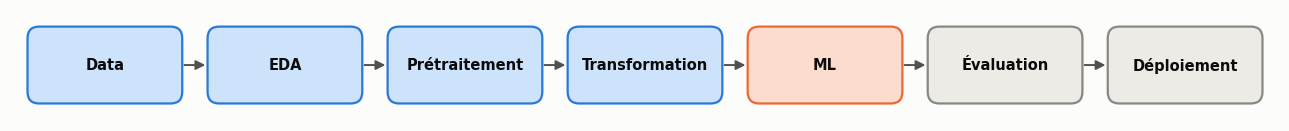

In [23]:
workflow(actif=5)

In [24]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def mesures(y_vrai_log, y_pred_log):
    vrai, pred = np.exp(y_vrai_log), np.exp(y_pred_log)
    return {"MAE (M¥)": mean_absolute_error(vrai, pred) / 1e6,
            "MAPE médiane (%)": np.median(np.abs(pred - vrai) / vrai) * 100,
            "R² (log)": r2_score(y_vrai_log, y_pred_log)}

# Référence : prix au m² médian de la commune (appris sur l'apprentissage) x surface
m2_commune = (np.exp(y_app) / X_app["surface_m2"]).groupby(X_app["commune"]).median()
pred_ref = np.log(X_test["commune"].map(m2_commune).fillna(m2_commune.median()) * X_test["surface_m2"])

resultats = {"Règle simple": {**mesures(y_test, pred_ref), "entraînement (s)": 0.0}}
modeles = {
    "Régression linéaire": Ridge(alpha=1.0),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.4,
                                             n_jobs=-1, random_state=0),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=800, learning_rate=0.1, max_leaf_nodes=63,
                                                       early_stopping=True, random_state=0),
}
pipelines, predictions = {}, {"Règle simple": pred_ref.to_numpy()}
for nom, modele in modeles.items():
    pipe = make_pipeline(preparation(), modele)
    t0 = time.perf_counter()
    pipe.fit(X_app, y_app)
    duree = time.perf_counter() - t0
    predictions[nom] = pipe.predict(X_test)
    pipelines[nom] = pipe
    resultats[nom] = {**mesures(y_test, predictions[nom]), "entraînement (s)": duree}
    print(f"{nom:20s} entraîné en {duree:5.1f} s")

tableau = pd.DataFrame(resultats).T
tableau

Régression linéaire  entraîné en   0.6 s


Forêt aléatoire      entraîné en  14.3 s


Gradient boosting    entraîné en  21.0 s


,MAE (M¥),MAPE médiane (%),R² (log),entraînement (s)
Règle simple,7.85,23.81,0.66,0.00
Régression linéaire,5.36,15.15,0.84,0.58
Forêt aléatoire,3.95,10.49,0.91,14.27
Gradient boosting,3.62,9.84,0.92,20.96


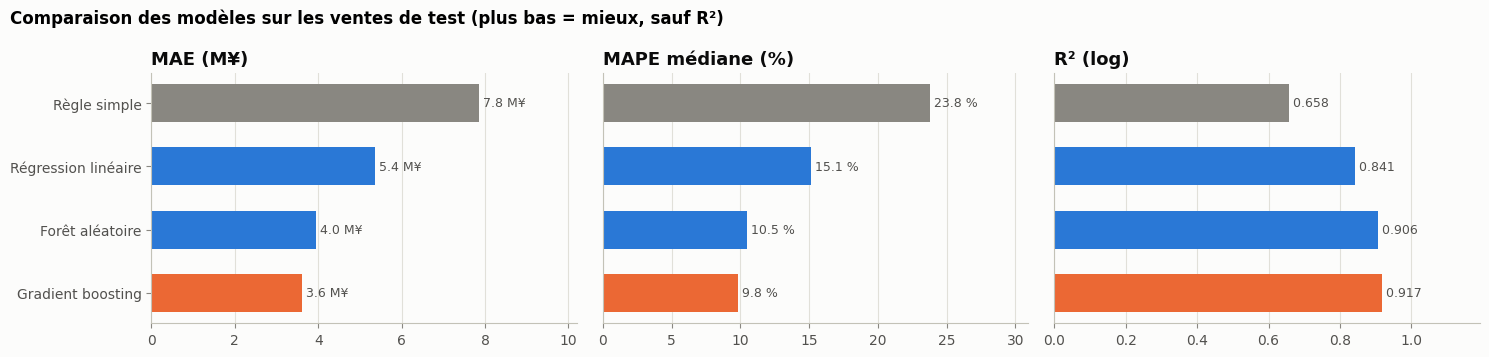

Meilleur modèle : Gradient boosting
OK     chaque modèle appris bat la règle simple (MAPE)
OK     le meilleur modèle explique plus de 90 % de la variance du log du prix  (R² = 0.917)


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ordre = tableau.index
couleurs = [GRIS, BLEU, BLEU, ORANGE]
for ax, col, fmt in zip(axes, ["MAE (M¥)", "MAPE médiane (%)", "R² (log)"], ["{:.1f} M¥", "{:.1f} %", "{:.3f}"]):
    ax.barh(ordre[::-1], tableau[col][::-1], color=couleurs[::-1], height=0.6)
    for i, v in enumerate(tableau[col][::-1]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9, color=ENCRE_2)
    ax.set_title(col); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, tableau[col].max() * 1.3)
axes[1].set_yticks([]); axes[2].set_yticks([])
fig.suptitle("Comparaison des modèles sur les ventes de test (plus bas = mieux, sauf R²)", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(); plt.show()

meilleur = tableau["MAPE médiane (%)"].idxmin()
print("Meilleur modèle :", meilleur)
verifier("chaque modèle appris bat la règle simple (MAPE)",
         all(tableau.loc[m, "MAPE médiane (%)"] < tableau.loc["Règle simple", "MAPE médiane (%)"] for m in modeles))
verifier("le meilleur modèle explique plus de 90 % de la variance du log du prix",
         tableau.loc[meilleur, "R² (log)"] > 0.90, f"R² = {tableau.loc[meilleur, 'R² (log)']:.3f}")

**Validation croisée.** Un seul découpage apprentissage/test peut avoir de la chance. On vérifie la stabilité
du gradient boosting par **validation croisée à 5 plis** : les données d'apprentissage sont coupées en 5 ; on
entraîne 5 fois sur 4 morceaux et on teste sur le 5ᵉ.

In [26]:
from sklearn.model_selection import cross_val_score, KFold
t0 = time.perf_counter()
scores = cross_val_score(make_pipeline(preparation(), HistGradientBoostingRegressor(
                             max_iter=800, learning_rate=0.1, max_leaf_nodes=63, early_stopping=True, random_state=0)),
                         X_app, y_app, cv=KFold(5, shuffle=True, random_state=1), scoring="r2", n_jobs=1)
print("R² des 5 plis :", np.round(scores, 4), f" moyenne {scores.mean():.4f} ± {scores.std():.4f}"
      f"   ({time.perf_counter() - t0:.0f} s)")
verifier("le R² varie de moins de 0,01 d'un pli à l'autre", scores.std() < 0.01, f"écart-type {scores.std():.4f}")

R² des 5 plis : [0.9142 0.9143 0.9143 0.9143 0.9163]  moyenne 0.9147 ± 0.0008   (55 s)
OK     le R² varie de moins de 0,01 d'un pli à l'autre  (écart-type 0.0008)


## 6. Évaluation : comprendre les erreurs du modèle

On examine le meilleur modèle sous plusieurs angles : la qualité des prédictions, les cas où il se trompe, les
variables qu'il utilise, et sa capacité à prédire **l'avenir**.

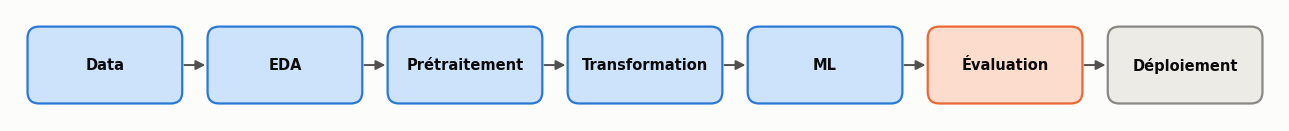

In [27]:
workflow(actif=6)

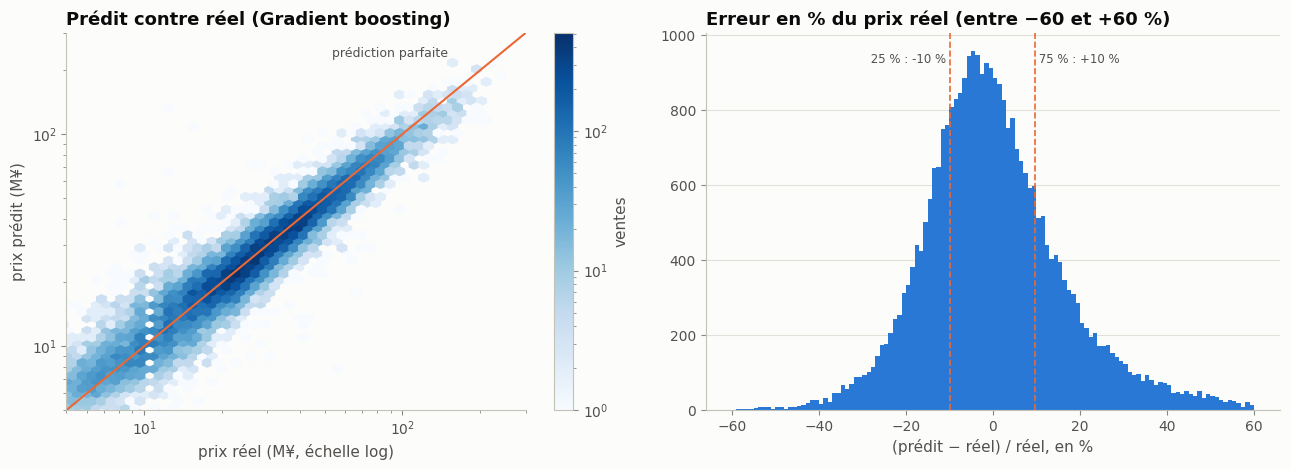

Prédictions à ±10 % : 51%   à ±20 % : 80%


In [28]:
pipe = pipelines[meilleur]
vrai, pred = np.exp(y_test) / 1e6, np.exp(predictions[meilleur]) / 1e6
ecart = (pred - vrai) / vrai * 100

fig, (g, d) = plt.subplots(1, 2, figsize=(13, 4.8))
hb = g.hexbin(vrai, pred, gridsize=60, bins="log", cmap=SEQUENTIEL, mincnt=1, xscale="log", yscale="log")
lim = [5, 300]
g.plot(lim, lim, color=ORANGE, lw=1.5)
g.text(150, 230, "prédiction parfaite", color=ENCRE_2, fontsize=9, ha="right")
g.set_xlim(lim); g.set_ylim(lim); g.set_xlabel("prix réel (M¥, échelle log)"); g.set_ylabel("prix prédit (M¥)")
g.set_title(f"Prédit contre réel ({meilleur})"); g.grid(False); fig.colorbar(hb, ax=g, label="ventes")

d.hist(ecart, bins=120, range=(-60, 60), color=BLEU)
for q, lab, cote in [(25, "25 %", "right"), (75, "75 %", "left")]:
    v = np.percentile(ecart, q); d.axvline(v, color=ORANGE, lw=1.2, ls="--")
    d.text(v, d.get_ylim()[1] * 0.92, f" {lab} : {v:+.0f} % ", fontsize=8.5, color=ENCRE_2, ha=cote)
d.set_title("Erreur en % du prix réel (entre −60 et +60 %)"); d.set_xlabel("(prédit − réel) / réel, en %"); d.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

dans_10 = (np.abs(ecart) <= 10).mean(); dans_20 = (np.abs(ecart) <= 20).mean()
print(f"Prédictions à ±10 % : {dans_10:.0%}   à ±20 % : {dans_20:.0%}")

**Et les ventes écartées par la règle f ?** Le nettoyage a retiré les 1 % de prix au m² les plus extrêmes, en
regardant le prix : le test ne contient donc que des prix plausibles, ce qui avantage les scores ci-dessus. On
mesure le même modèle sur ces ventes écartées pour voir ce qui se passerait face à elles.

In [29]:
pred_f = np.exp(pipe.predict(tokyo_prep.variables(exclus_f)))
ecart_f = np.abs(pred_f - exclus_f["TradePrice"].to_numpy()) / exclus_f["TradePrice"].to_numpy() * 100
print(f"{len(exclus_f):,} ventes écartées par la règle f : erreur médiane {np.median(ecart_f):.0f} % "
      f"(contre {np.median(np.abs(ecart)):.1f} % sur le test)")

1,618 ventes écartées par la règle f : erreur médiane 89 % (contre 9.8 % sur le test)


Erreur médiane de 89 % : ces ventes ne suivent pas le marché (prix symboliques, ventes en bloc, erreurs de saisie). Aucun modèle fondé sur la surface, l'âge et l'emplacement ne peut les prédire. Les scores ci-dessus valent donc pour des ventes **à prix de marché** ; en pratique, un écart de plus de 50 % entre le prix annoncé et l'estimation signale justement une vente à vérifier.

Les points suivent la diagonale. La moitié des prédictions tombe entre les deux traits orange. Les plus
grosses erreurs viennent d'informations **absentes des données** : l'étage, la vue, l'état intérieur, la
taille de l'immeuble... Le modèle ne peut pas les deviner.

### 6.1 Erreur par commune

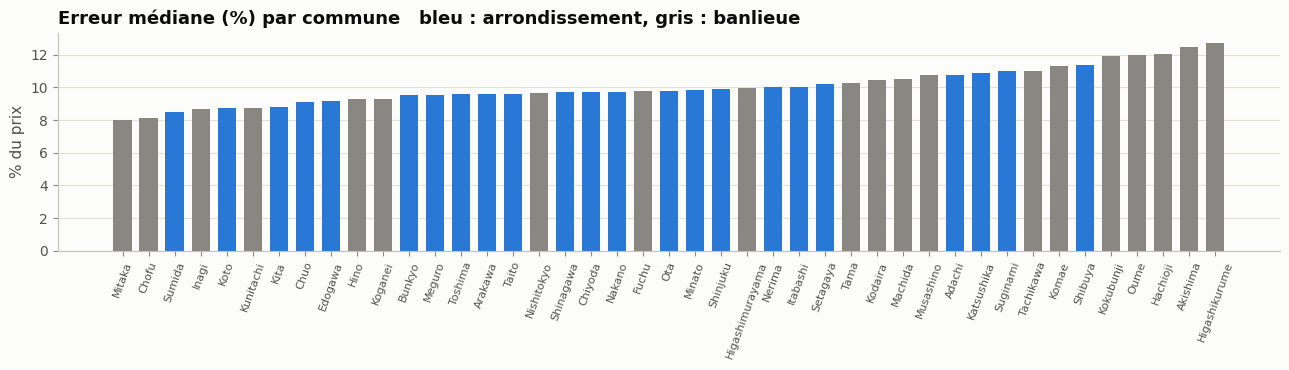

In [30]:
err_commune = pd.DataFrame({"commune": X_test["commune"].to_numpy(), "err": np.abs(ecart)})
err_commune = err_commune.groupby("commune")["err"].agg(["median", "size"])
err_commune = err_commune[err_commune["size"] >= 100].sort_values("median")
fig, ax = plt.subplots(figsize=(13, 3.8))
coul = [BLEU if c.endswith("Ward") else GRIS for c in err_commune.index]
ax.bar([c.replace(" Ward", "").replace(" City", "") for c in err_commune.index], err_commune["median"],
       color=coul, width=0.7)
ax.set_title("Erreur médiane (%) par commune   bleu : arrondissement, gris : banlieue")
ax.set_ylabel("% du prix"); ax.tick_params(axis="x", rotation=70, labelsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

L'erreur médiane reste entre 8 et 13 % partout : le modèle marche aussi bien dans le centre qu'en banlieue.
Les communes les plus difficiles sont des villes éloignées (Higashikurume, Akishima, Hachioji, Oume), où il y a
moins de ventes pour apprendre, et Shibuya, où les écarts entre appartements de luxe et studios sont grands.

### 6.2 Quelles variables comptent ?

**Importance par permutation** : on mélange au hasard une variable dans les données de test et on regarde de
combien le modèle se dégrade. Plus il se dégrade, plus il comptait sur cette variable.

calculé en 8 s


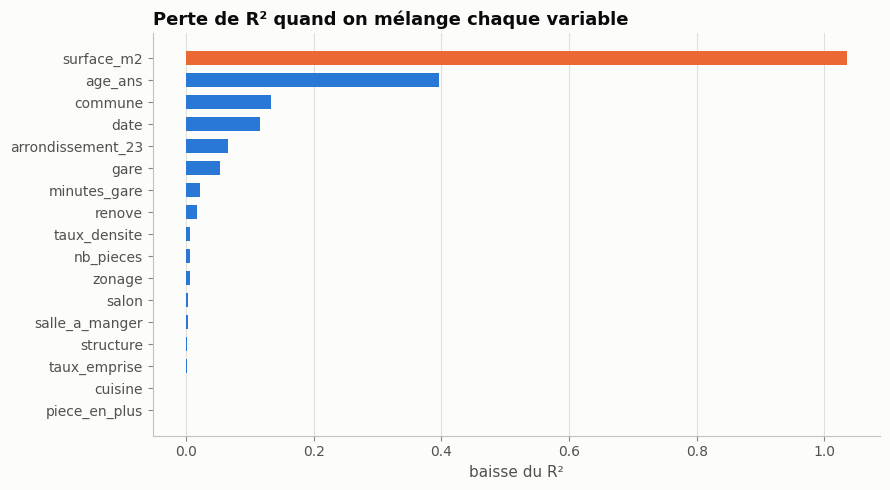

OK     la surface fait partie des 3 variables les plus importantes


In [31]:
from sklearn.inspection import permutation_importance
echantillon = X_test.sample(5000, random_state=0)
t0 = time.perf_counter()
imp = permutation_importance(pipe, echantillon, y_test[X_test.index.get_indexer(echantillon.index)],
                             n_repeats=5, random_state=0, scoring="r2", n_jobs=1)
imp = pd.Series(imp.importances_mean, index=echantillon.columns).sort_values()
print(f"calculé en {time.perf_counter() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=[ORANGE if v == imp.max() else BLEU for v in imp.values], height=0.65)
ax.set_title("Perte de R² quand on mélange chaque variable"); ax.set_xlabel("baisse du R²")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
verifier("la surface fait partie des 3 variables les plus importantes", "surface_m2" in imp.index[-3:])

Sans surprise, la **surface** domine : elle fixe l'ordre de grandeur du prix. Viennent ensuite **l'âge**,
**l'emplacement** (commune, arrondissement ou non, gare, minutes à pied) et la **date**. Les règles
d'urbanisme (densité, emprise, zonage) ne comptent presque plus : la commune et la gare disent déjà où l'on est. Le plan (nombre de pièces, salon...)
compte peu : la surface dit déjà presque tout.

### 6.3 Plus de données, meilleur modèle ?

**Courbe d'apprentissage** : on entraîne le gradient boosting sur 1 %, 5 %, 10 %... des données
d'apprentissage et on mesure l'erreur sur le même test. C'est la question qui mène au Big Data : **faut-il plus
de données ?**

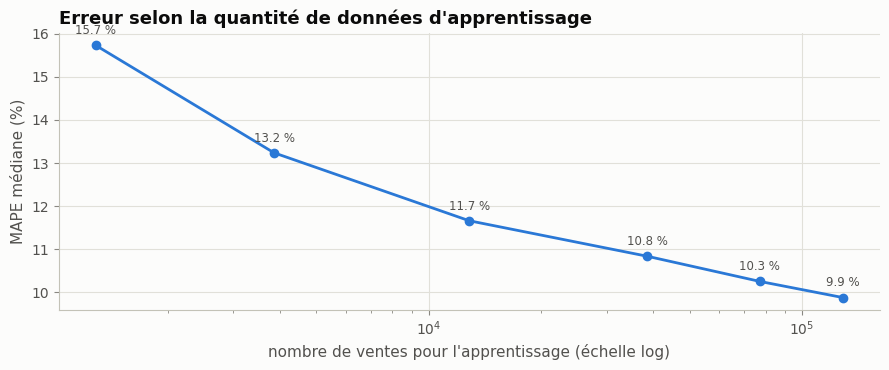

,ventes,MAE (M¥),MAPE médiane (%),R² (log)
0,1285,5.84,15.73,0.83
1,3855,4.90,13.24,0.87
2,12850,4.33,11.66,0.89
3,38550,3.98,10.84,0.91
4,77100,3.77,10.25,0.91
5,128500,3.63,9.88,0.92


In [32]:
tailles = [0.01, 0.03, 0.1, 0.3, 0.6, 1.0]
courbe = []
for p in tailles:
    sous = X_app.sample(frac=p, random_state=0)
    m = make_pipeline(preparation(), HistGradientBoostingRegressor(max_iter=800, learning_rate=0.1,
                      max_leaf_nodes=63, early_stopping=True, random_state=0))
    m.fit(sous, y_app[X_app.index.get_indexer(sous.index)])
    courbe.append({"ventes": len(sous), **mesures(y_test, m.predict(X_test))})
courbe = pd.DataFrame(courbe)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(courbe["ventes"], courbe["MAPE médiane (%)"], color=BLEU, marker="o")
for _, r in courbe.iterrows():
    ax.annotate(f"{r['MAPE médiane (%)']:.1f} %", (r["ventes"], r["MAPE médiane (%)"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color=ENCRE_2)
ax.set_xscale("log"); ax.set_xlabel("nombre de ventes pour l'apprentissage (échelle log)")
ax.set_ylabel("MAPE médiane (%)"); ax.set_title("Erreur selon la quantité de données d'apprentissage")
plt.tight_layout(); plt.show()
courbe.round(3)

L'erreur baisse vite au début, puis **la courbe s'aplatit** : passer de 60 % à 100 % des données ne gagne
presque plus rien. Pour ce problème, quelques dizaines de milliers de ventes suffisent ; des données en plus,
ce sont surtout des **variables en plus** (étage, orientation...) qui aideraient. C'est une bonne raison de ne
**pas** faire de Big Data ici : pandas et un ordinateur portable suffisent largement.

### 6.4 Prédire l'avenir

Jusqu'ici, le test était tiré au hasard sur 2005-2019 : le modèle avait vu des ventes de toutes les années.
Que se passe-t-il si on l'entraîne sur **2005-2017** et qu'on lui demande les prix de **2018-2019**, comme dans
la vraie vie ?

In [33]:
passe = X["date"] < 2018
m_passe = make_pipeline(preparation(), HistGradientBoostingRegressor(max_iter=800, learning_rate=0.1,
                        max_leaf_nodes=63, early_stopping=True, random_state=0)).fit(X[passe], y[passe])
pred_futur = m_passe.predict(X[~passe])
biais = np.median(np.exp(pred_futur) / np.exp(y[~passe]) - 1) * 100
futur = pd.DataFrame({"test au hasard (2005-2019)": tableau.loc[meilleur, ["MAE (M¥)", "MAPE médiane (%)", "R² (log)"]],
                      "test sur l'avenir (2018-2019)": pd.Series(mesures(y[~passe], pred_futur))})
print(f"Entraîné sur {passe.sum():,} ventes, testé sur {(~passe).sum():,} ventes de 2018-2019")
print(f"Biais médian : {biais:+.1f} % (négatif = le modèle sous-estime)")
futur

Entraîné sur 136,884 ventes, testé sur 23,742 ventes de 2018-2019
Biais médian : -6.0 % (négatif = le modèle sous-estime)


,test au hasard (2005-2019),test sur l'avenir (2018-2019)
MAE (M¥),3.62,4.47
MAPE médiane (%),9.84,11.06
R² (log),0.92,0.89


L'erreur augmente et le modèle **sous-estime** les prix : les arbres de décision ne savent pas prolonger une
tendance. Pour une date jamais vue (2018), ils répondent comme pour la dernière date connue (fin 2017), alors
que les prix ont continué de monter. En pratique, il faut **réentraîner le modèle régulièrement** avec les
ventes récentes. C'est ce qu'on fait pour le déploiement : le modèle final est entraîné sur toutes les ventes.

## 7. Déploiement : servir le modèle

Déployer, c'est rendre le modèle **utilisable par quelqu'un d'autre que son auteur**. Ici :

1. on entraîne le modèle final sur **toutes** les ventes nettoyées ;
2. on le sauvegarde dans un fichier avec `joblib` (le Pipeline entier : préparation + modèle) ;
3. une petite appli web **Streamlit** (`app_tokyo.py`) le recharge et estime le prix d'un appartement décrit
   dans un formulaire.

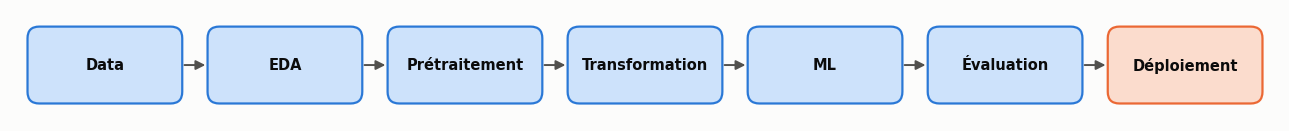

In [34]:
workflow(actif=7)

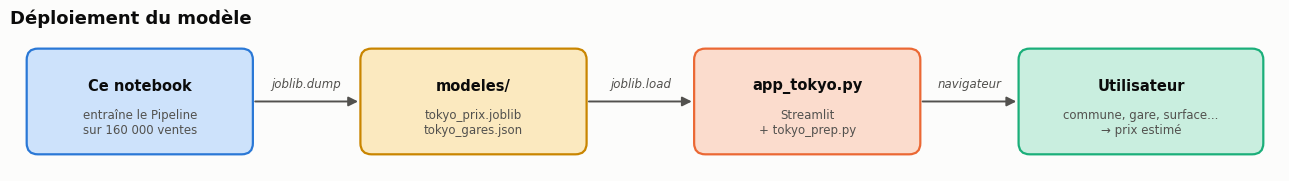

In [35]:
schema([
    dict(id="nb", x=0, y=0, texte="Ce notebook", sous="entraîne le Pipeline\nsur 160 000 ventes", couleur="bleu", l=2.4, h=1.1),
    dict(id="mod", x=3.6, y=0, texte="modeles/", sous="tokyo_prix.joblib\ntokyo_gares.json", couleur="jaune", l=2.4, h=1.1),
    dict(id="app", x=7.2, y=0, texte="app_tokyo.py", sous="Streamlit\n+ tokyo_prep.py", couleur="orange", l=2.4, h=1.1),
    dict(id="user", x=10.8, y=0, texte="Utilisateur", sous="commune, gare, surface...\n→ prix estimé", couleur="vert", l=2.6, h=1.1),
], [("nb", "mod", "joblib.dump"), ("mod", "app", "joblib.load"), ("app", "user", "navigateur")],
   taille=(13, 2.2), titre="Déploiement du modèle")

In [36]:
t0 = time.perf_counter()
final = make_pipeline(preparation(), HistGradientBoostingRegressor(max_iter=800, learning_rate=0.1,
                      max_leaf_nodes=63, early_stopping=True, random_state=0)).fit(X, y)
print(f"Modèle final entraîné sur {len(X):,} ventes en {time.perf_counter() - t0:.0f} s")

Path("modeles").mkdir(exist_ok=True)
joblib.dump(final, "modeles/tokyo_prix.joblib", compress=3)

# Pour le formulaire : la liste des gares de chaque commune et, pour chaque gare, les valeurs d'urbanisme les
# plus fréquentes (zonage, densité...), que l'utilisateur ne connaît pas.
def mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else None

gares = {}
for (commune, gare), g in propre.groupby(["Municipality", "NearestStation"]):
    if len(g) >= 20:
        gares.setdefault(commune, {})[gare] = {
            "ventes": int(len(g)), "CityPlanning": mode(g["CityPlanning"]), "Structure": mode(g["Structure"]),
            "CoverageRatio": float(g["CoverageRatio"].median()), "FloorAreaRatio": float(g["FloorAreaRatio"].median())}
Path("modeles/tokyo_gares.json").write_text(json.dumps(gares, ensure_ascii=False, indent=1), encoding="utf-8")
for f in ["modeles/tokyo_prix.joblib", "modeles/tokyo_gares.json"]:
    print(f"{f:30s} {Path(f).stat().st_size / 1e6:.2f} Mo")
print(sum(len(v) for v in gares.values()), "gares dans", len(gares), "communes")

Modèle final entraîné sur 160,626 ventes en 15 s


modeles/tokyo_prix.joblib      2.07 Mo
modeles/tokyo_gares.json       0.12 Mo
702 gares dans 48 communes


On vérifie que le modèle **rechargé depuis le disque** donne exactement les mêmes prédictions, puis on estime
quelques appartements, comme le ferait l'appli.

In [37]:
recharge = joblib.load("modeles/tokyo_prix.joblib")
verifier("le modèle rechargé prédit exactement comme l'original",
         np.allclose(recharge.predict(X_test.head(1000)), final.predict(X_test.head(1000))))

def estimer(commune, gare, surface, annee_construction, minutes, plan, renove=False, annee=2019, trimestre=3):
    # Estime le prix (en yens) d'un appartement : même calcul que dans app_tokyo.py
    infos = gares[commune][gare]
    ligne = pd.DataFrame([{"Municipality": commune, "NearestStation": gare, "MinTimeToNearestStation": minutes,
                           "Area": surface, "FloorPlan": plan, "BuildingYear": annee_construction,
                           "Structure": infos["Structure"], "Renovation": "Done" if renove else "Not yet",
                           "CityPlanning": infos["CityPlanning"], "CoverageRatio": infos["CoverageRatio"],
                           "FloorAreaRatio": infos["FloorAreaRatio"], "Year": annee, "Quarter": trimestre}])
    return float(np.exp(recharge.predict(tokyo_prep.variables(ligne))[0]))

exemples = [("Minato Ward", "Roppongi", 55, 2005, 5, "2LDK"),
            ("Setagaya Ward", "Sangenjaya", 55, 2005, 5, "2LDK"),
            ("Setagaya Ward", "Sangenjaya", 55, 1985, 5, "2LDK"),
            ("Setagaya Ward", "Sangenjaya", 25, 2005, 5, "1K"),
            ("Hachioji City", "Hachioji", 55, 2005, 5, "2LDK")]
lignes = []
for commune, gare, surf, an, mn, plan in exemples:
    p = estimer(commune, gare, surf, an, mn, plan)
    lignes.append({"commune": commune, "gare": gare, "surface": surf, "construit en": an, "plan": plan,
                   "prix estimé (M¥)": round(p / 1e6, 1), "k¥/m²": round(p / surf / 1e3)})
estimations = pd.DataFrame(lignes)
display(estimations)
e = estimations["prix estimé (M¥)"]
verifier("même appartement : Roppongi (Minato) plus cher que Sangenjaya (Setagaya), plus cher que Hachioji",
         e[0] > e[1] > e[4], list(e))
verifier("à Sangenjaya, l'immeuble de 1985 vaut moins que celui de 2005", e[2] < e[1])

OK     le modèle rechargé prédit exactement comme l'original


,commune,gare,surface,construit en,plan,prix estimé (M¥),k¥/m²
0,Minato Ward,Roppongi,55,2005,2LDK,64.20,1168
1,Setagaya Ward,Sangenjaya,55,2005,2LDK,53.20,967
2,Setagaya Ward,Sangenjaya,55,1985,2LDK,37.40,680
3,Setagaya Ward,Sangenjaya,25,2005,1K,26.10,1043
4,Hachioji City,Hachioji,55,2005,2LDK,23.30,424


OK     même appartement : Roppongi (Minato) plus cher que Sangenjaya (Setagaya), plus cher que Hachioji  ([64.2, 53.2, 37.4, 26.1, 23.3])
OK     à Sangenjaya, l'immeuble de 1985 vaut moins que celui de 2005


Les estimations sont cohérentes avec l'EDA : à appartement identique, Roppongi (centre, Minato) coûte
nettement plus que Sangenjaya (Setagaya, résidentiel), qui coûte plus que Hachioji (banlieue lointaine) ; un
immeuble de 20 ans de plus fait baisser le prix.

### L'appli Streamlit

```bash
pip install streamlit
streamlit run app_tokyo.py
```

Le navigateur s'ouvre sur un formulaire : commune, gare, surface, plan, année de construction, minutes à pied,
rénovation. L'appli affiche le prix estimé, le prix au m² et une fourchette (l'intervalle où tombent la moitié
des ventes réelles de test, d'après l'erreur mesurée en partie 6).

In [38]:
# Fourchette affichée par l'appli : quartiles de l'erreur relative mesurée sur le test
q25, q75 = np.percentile(np.exp(y_test) / np.exp(predictions[meilleur]), [25, 75])
Path("modeles/tokyo_fourchette.json").write_text(json.dumps({"bas": q25, "haut": q75}), encoding="utf-8")
print(f"La moitié des prix réels tombent entre {q25:.2f} et {q75:.2f} fois la prédiction")

La moitié des prix réels tombent entre 0.91 et 1.11 fois la prédiction

## 8. Bilan des tests

In [39]:
bilan_tests()

15 tests réussis sur 15


,test,résultat,détail
0,406 575 ventes et 38 colonnes dans le fichier ...,OK,"(406575, 38)"
1,184 331 appartements d'occasion,OK,184331
2,le nettoyage garde plus de 85 % des appartements,OK,87.1%
3,plus aucun doublon,OK,
4,aucun âge négatif,OK,
5,aucune valeur manquante dans la cible,OK,
6,"les plans 2LDK+S, 1K et 1R sont bien lus (pièc...",OK,"[[2.0, 1.0, 1.0, 1.0, 1.0], [1.0, 0.0, 0.0, 1...."
7,aucune vente à la fois en apprentissage et en ...,OK,
8,chaque modèle appris bat la règle simple (MAPE),OK,
9,le meilleur modèle explique plus de 90 % de la...,OK,R² = 0.917


## Conclusion

| Étape | Ce qu'on a fait | Ce qu'on retient |
|---|---|---|
| **Data** | 406 575 ventes du fichier de Tokyo, dont 184 331 appartements d'occasion | un fichier de 104 Mo : pandas le lit en quelques secondes |
| **EDA** | prix, communes, surface, âge, gare, évolution, plans, corrélations | le prix s'étale sur plusieurs ordres de grandeur ; l'emplacement, la surface et l'âge le déterminent |
| **Prétraitement** | 7 règles de nettoyage | on garde plus de 85 % des ventes ; on retire les enchères, doublons et valeurs aberrantes |
| **Transformation** | variables calculées, one-hot, encodage par la cible, log du prix | tout est dans un Pipeline : pas de fuite du test vers l'apprentissage (seule la règle f du nettoyage regarde le prix, mesurée à part en 6) |
| **ML** | règle simple, régression linéaire, forêt aléatoire, gradient boosting | le gradient boosting est le meilleur, et de loin meilleur que la règle simple |
| **Évaluation** | erreurs, communes, importance des variables, courbe d'apprentissage, test sur l'avenir | la moitié des estimations à environ ±10 % ; plus de données n'aide plus beaucoup ; il faut réentraîner avec les ventes récentes |
| **Déploiement** | modèle sauvegardé + appli Streamlit | l'appli réutilise `tokyo_prep.py` : mêmes calculs qu'à l'entraînement |

**Pourquoi pas de Big Data ici ?** 160 000 lignes tiennent largement en mémoire (le fichier entier occupe
moins de 500 Mo), l'entraînement prend moins d'une minute et la courbe d'apprentissage montre que plus de lignes n'apporterait presque rien. Le second
notebook, `chicago_velos.ipynb`, traite un cas où les données (5,9 millions de trajets, 1,1 Go) justifient
Hadoop et Spark.